# ⚙️ Predicting Industrial Equipment Failure from Sensor Data

**A complete, honest walkthrough:** dataset → cleaning → modelling → evaluation → prediction → dashboard.

| | |
|---|---|
| **Dataset** | AI4I 2020 Predictive Maintenance (UCI ML Repository, ID 601) — 10,000 records, simulated |
| **Task** | Binary classification: will this machine run fail? (`Machine failure` = 1) |
| **Models** | Logistic Regression · Decision Tree · Random Forest |
| **Imbalance policy** | `class_weight='balanced'`, threshold tuned on training folds only |
| **Deliverable** | This notebook + a Streamlit dashboard + a written report |

> ⚠️ **Read this first.** Every number in this notebook is a *probability estimated from
> simulated data*. Nothing here predicts a guaranteed equipment failure. Use it to
> prioritise human inspection, never to certify that a machine is safe.

This notebook is the *narrative* version of the pipeline. The modules in `src/` are the
production version, and the dashboard imports exactly the same code, so the numbers you
see here are the numbers the app uses.

## The workflow

```
   data/raw_ai4i2020.csv
            │
            ▼
   ①  IMPORT + CLEAN          src/cleaning.py     audit → coerce → validate ranges →
            │                                      dedupe → impute → flag outliers
            ▼
   ②  FEATURE ENGINEERING     src/cleaning.py     physics-motivated derived features
            │
            ▼
   ③  MODEL TRAINING          src/modeling.py     LR / DT / RF, class-weighted,
            │                                      random split + temporal split
            ▼
   ④  EVALUATION              sklearn.metrics     precision, recall, F1, PR-AUC,
            │                                      confusion matrices, bootstrap CIs
            ▼
   ⑤  EXPLANATION             sklearn.inspection  permutation importance, Gini,
            │                                      LR coefficients, partial dependence
            ▼
   ⑥  PREDICTION + DASHBOARD  app/streamlit_app.py  single machine + batch scoring
```

Nothing is hidden: every decision is a documented constant in `src/config.py`.

In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config as C
from src import cleaning, modeling

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print("random_state      :", C.RANDOM_STATE)
print("test size         :", C.TEST_SIZE)
print("CV folds          :", C.CV_FOLDS)
print("engineered feats  :", C.ADD_ENGINEERED_FEATURES)
print("IDs as features   :", C.USE_ID_COLUMNS_AS_FEATURES)
print("leakage cols (out):", C.FAILURE_MODE_COLS)

random_state      : 42
test size         : 0.2
CV folds          : 5
engineered feats  : True
IDs as features   : True
leakage cols (out): ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']


---
## ① The dataset

**AI4I 2020 Predictive Maintenance Dataset** (UCI Machine Learning Repository, ID 601).

It describes a synthetic milling-machine process with 10,000 independent runs. Each row is
one run with five sensors plus a machine grade:

| Column | Meaning | Unit |
|---|---|---|
| `Air temperature` | ambient temperature around the machine | K |
| `Process temperature` | temperature of the working process | K |
| `Rotational speed` | spindle speed | rpm |
| `Torque` | torque on the tool | Nm |
| `Tool wear` | cumulative minutes of use for the tool | min |
| `Type` | machine grade: **L** (low, 60%), **M** (medium, 30%), **H** (high, 10%) | — |
| `Machine failure` | **target**: 1 if the run ended in failure | 0/1 |
| `TWF, HDF, PWF, OSF, RNF` | which of five failure modes occurred | 0/1 |

Let's load it raw and audit it before changing anything.

In [2]:
raw = cleaning.read_raw()
audit = cleaning.audit(raw)

print(f"shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"missing cells      : {audit['missing_total']}")
print(f"duplicate rows     : {audit['duplicate_rows']}")
print(f"failures           : {audit['failure_count']} ({audit['failure_rate']:.2%})")
print(f"machine types      : {audit['machine_type_counts']}")
raw.head()

shape: 10,000 rows x 14 columns
missing cells      : 0
duplicate rows     : 0
failures           : 339 (3.39%)
machine types      : {'L': 6000, 'M': 2997, 'H': 1003}


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,4,L47183,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,5,L47184,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


In [3]:
raw.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]

,mean,std,min,25%,50%,75%,max
UDI,"5,000.500","2,886.896",1.000,"2,500.750","5,000.500","7,500.250","10,000.000"
Air temperature [K],300.005,2.000,295.300,298.300,300.100,301.500,304.500
Process temperature [K],310.006,1.484,305.700,308.800,310.100,311.100,313.800
Rotational speed [rpm],"1,538.776",179.284,"1,168.000","1,423.000","1,503.000","1,612.000","2,886.000"
Torque [Nm],39.987,9.969,3.800,33.200,40.100,46.800,76.600
Tool wear [min],107.951,63.654,0.000,53.000,108.000,162.000,253.000
Machine failure,0.034,0.181,0.000,0.000,0.000,0.000,1.000
TWF,0.005,0.068,0.000,0.000,0.000,0.000,1.000
HDF,0.011,0.107,0.000,0.000,0.000,0.000,1.000
PWF,0.009,0.097,0.000,0.000,0.000,0.000,1.000


### What this dataset is good for — and what it is not

**Good:**
- Exactly the sensor set a maintenance team would actually have.
- Labelled failures *and* labelled failure modes, so evaluation is unambiguous.
- Small enough to iterate quickly, free, and widely used — results are comparable.

**Limitations (these matter more than the accuracy numbers):**

1. **It is simulated.** The data was generated from a physics-inspired process model, not
   logged from real machines. Real streams have sensor drift, correlated channels,
   dropouts, maintenance interventions and operator behaviour that this data lacks.
2. **Failures are rare** — 339 out of 10,000 (3.4%). Statistics on 68 test-set failures
   are inherently noisy; confidence intervals below are wide for good reason.
3. **19 `RNF` (random failure) records are unlearnable by construction.** They fail with no
   sensor signature. No model can catch them, and they put a hard ceiling on recall.
4. **Tool-wear failure is truncated.** Every `TWF` record in this dataset occurs at tool wear
   of 198–253 min, i.e. only just before the replacement limit. So `TWF` is partly an artefact
   of the tool-replacement policy rather than pure physics, and a model cannot learn much about
   early-stage wear failure from it.
5. **No time dimension per machine.** Each row is an independent run, so a real
   per-asset degradation history cannot be modelled here.

Target balance
                 records  share
Machine failure                
0                   9661  0.966
1                    339  0.034

Failure modes
     records
HDF      115
OSF       98
PWF       95
TWF       46
RNF       19

Machine type breakdown
Machine failure     0    1    All
Type                             
H                 982   21   1003
L                5765  235   6000
M                2914   83   2997
All              9661  339  10000


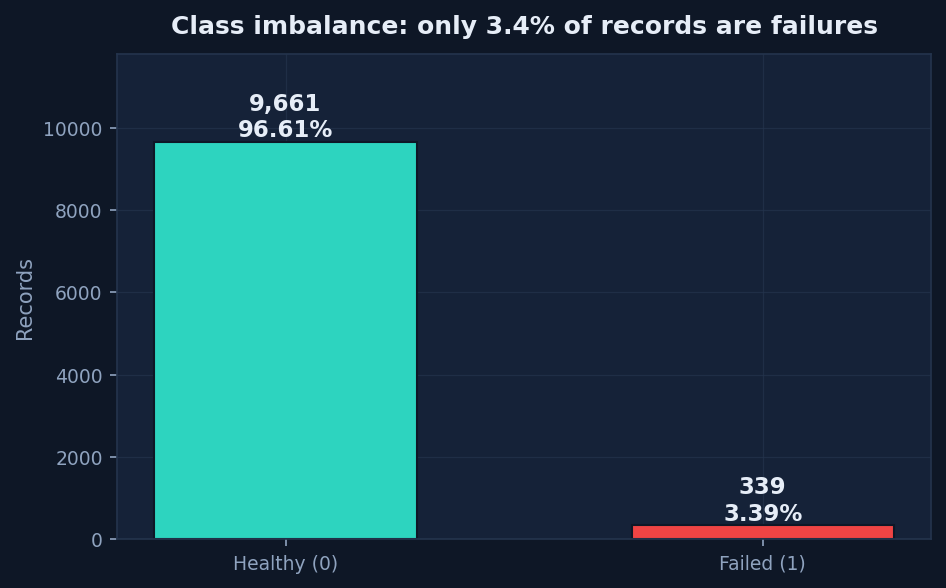

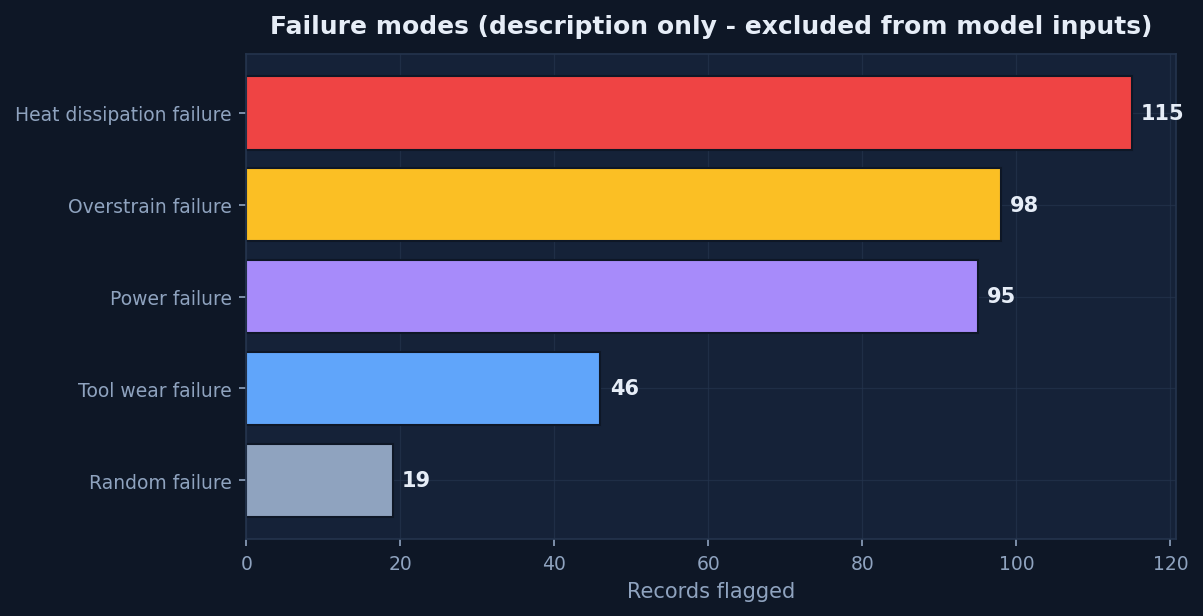

In [4]:
# Class balance and the five failure modes
counts = raw[C.TARGET].value_counts().sort_index()
modes = raw[C.FAILURE_MODE_COLS].sum().sort_values(ascending=False)

print("Target balance")
print(pd.DataFrame({"records": counts, "share": counts / len(raw)}))
print("\nFailure modes")
print(modes.to_frame("records"))
print("\nMachine type breakdown")
print(pd.crosstab(raw["Type"], raw[C.TARGET], margins=True))

display(Image(filename=str(C.FIG_DIR / "01_class_imbalance.png"), width=620))
display(Image(filename=str(C.FIG_DIR / "04_failure_modes.png"), width=620))

---
## ② The data-leakage trap (worth understanding before modelling)

Those five failure-mode columns look like helpful features. **They are the answer in disguise.**

A failure-mode flag is only set *because* a failure happened, so a column like `HDF` is a
near-perfect predictor — but it can never be known *before* the failure, which makes it
useless in production and guaranteed to inflate any test score.

Let's prove the relationship, then remove them.

In [5]:
mode_sum = raw[C.FAILURE_MODE_COLS].sum(axis=1)
print(pd.crosstab(mode_sum.rename("number of mode flags"), raw[C.TARGET].rename("Machine failure")))

flag_no_failure = int(((mode_sum > 0) & (raw[C.TARGET] == 0)).sum())
failure_no_flag = int(((mode_sum == 0) & (raw[C.TARGET] == 1)).sum())
print(f"\nrows flagging a mode but labelled healthy : {flag_no_failure}")
print(f"rows labelled failed with no mode flagged : {failure_no_flag}")
print(f"perfect reconstruction (sum == target)    : {bool((mode_sum == raw[C.TARGET]).all())}")

Machine failure          0    1
number of mode flags           
0                     9643    9
1                       18  306
2                        0   23
3                        0    1

rows flagging a mode but labelled healthy : 18
rows labelled failed with no mode flagged : 9
perfect reconstruction (sum == target)    : False


Two findings here:

1. The flags are an almost-exact but **not perfect** function of the target: 18 rows flag a
   mode while `Machine failure` is 0, and 9 failures carry no flag. So the dataset has a
   small amount of **label noise** — a limitation, not something to "fix" by overwriting the
   published labels (we deliberately do *not* rewrite the target from a leaked column).
2. Because a mode flag is only observable *after* failure, **all five columns are excluded
   from every model input** in this project. They are used only for the descriptive chart above.

---
## ③ Cleaning

Because the raw data is already clean, a "cleaning step" could easily be theatre. To make it
honest and genuinely useful, the pipeline is:

1. kept as a **reusable module** (`src/cleaning.py`) that real messy files can go through, and
2. **validated on a deliberately corrupted copy** of the dataset — proof that it works.

The pipeline performs: type coercion → machine-type normalisation → physical range validation
→ duplicate removal → label-integrity check → median imputation → IQR outlier *flagging*
(never silent deletion — an extreme reading may be the failure symptom we are looking for).

In [6]:
clean_out = cleaning.run(corrupt_test=True)
summary = clean_out["summary"]

print("=== real data ===")
print(f"rows in {summary['rows_in']:,} -> rows out {summary['rows_out']:,} "
      f"(removed {summary['rows_removed']})")
for s in summary["log"]:
    print(f"  - {s['step']:<20} {s['detail']}")

ct = summary["corruption_test"]
print("\n=== deliberately corrupted copy (pipeline validation) ===")
print(f"injected missing cells : {ct['injected_missing']}")
print(f"injected duplicate rows: {ct['injected_duplicates']}")
print(f"rows before -> after   : {ct['rows_before']:,} -> {ct['rows_after']:,}")
print(f"all duplicates recovered: {ct['pipeline_recovered']}")
actions = pd.DataFrame([{"step": a["step"], "what happened": a["detail"],
                         "rows": a["rows_affected"]} for a in ct["actions"]])
actions

=== real data ===
rows in 10,000 -> rows out 10,000 (removed 0)
  - coerce_numeric       coerced 0 non-numeric sensor values to NaN
  - normalise_type       normalised 0 machine-type labels
  - range_validation     0 impossible sensor readings (>physical limits) set to missing
  - drop_duplicates      removed 0 duplicate rows
  - target_integrity     18 rows flag a failure mode but are labelled healthy; 9 labelled failures have no mode flag. Published target preserved unchanged (documented limitation).
  - impute_median        median-imputed 0 cells
  - outlier_flag         flagged 106 statistically extreme values (IQR x3.0) - kept, not deleted

=== deliberately corrupted copy (pipeline validation) ===
injected missing cells : 302
injected duplicate rows: 50
rows before -> after   : 10,050 -> 10,000
all duplicates recovered: True


,step,what happened,rows
0,coerce_numeric,coerced 6 non-numeric sensor values to NaN,6
1,normalise_type,normalised 8 machine-type labels,8
2,range_validation,10 impossible sensor readings (>physical limit...,10
3,drop_duplicates,removed 50 duplicate rows,50
4,target_integrity,18 rows flag a failure mode but are labelled h...,27
5,impute_median,median-imputed 316 cells,316
6,outlier_flag,flagged 110 statistically extreme values (IQR ...,110


The corrupted copy had impossible readings (negative torque, 99,999 rpm), inconsistent
machine-type labels (`" m "`), a temperature column stored as text, 302 missing cells and 50
duplicate rows. The pipeline repaired all of it and recovered exactly 50 duplicate rows —
so the cleaning code is demonstrably functional rather than decorative.

The cleared dataset now has the engineered features added:

In [7]:
df = clean_out["data"]
print(f"cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
new_cols = [c for c in C.ENGINEERED_COLS]
df[new_cols + [C.TARGET]].describe().T[["mean", "std", "min", "50%", "max"]]

cleaned dataset: 10,000 rows x 25 columns


,mean,std,min,50%,max
Temp difference [K],10.001,1.001,7.600,9.800,12.100
Mechanical power [kW],6.280,1.067,1.148,6.271,10.470
Wear-torque interaction,"4,314.665","2,826.568",0.000,"4,012.950","16,497.000"
Speed-torque ratio,43.167,25.054,15.666,37.404,759.474
Wear rate [min per kW],17.754,11.277,0.000,17.058,128.208
Machine failure,0.034,0.181,0.000,0.000,1.000


### Why these engineered features?

Each one encodes a mechanism a maintenance engineer would recognise:

| Feature | Formula | Physical reasoning |
|---|---|---|
| `Temp difference [K]` | process − air temp | A large gap means heat is being generated faster than it dissipates → **HDF** (heat dissipation failure). |
| `Mechanical power [kW]` | torque × ω | The actual load on the tool, not just torque. High power at low speed means a strained cutting regime → **OSF/PWF**. |
| `Wear-torque interaction` | wear × torque | A worn tool still under heavy load is the classic strain accumulation path → **OSF/TWF**. |
| `Speed-torque ratio` | rpm / torque | Captures the operating *point* shape, which separates the failure region. |
| `Wear rate [min per kW]` | wear / power | How much tool life is being consumed per unit of work. |

These are not arbitrary polynomial expansions: each has a stated mechanism, which is what
makes the resulting explanations defensible.

In [8]:
corr = df[C.SENSOR_COLS + C.ENGINEERED_COLS + [C.TARGET]].corr()[C.TARGET]
corr = corr.drop(C.TARGET).sort_values(key=abs, ascending=False)
print("Correlation of each feature with the target (Pearson r):")
print(corr.to_frame("r with failure").round(3))

Correlation of each feature with the target (Pearson r):
                         r with failure
Torque [Nm]                       0.191
Wear-torque interaction           0.190
Mechanical power [kW]             0.176
Temp difference [K]              -0.112
Tool wear [min]                   0.105
Air temperature [K]               0.083
Wear rate [min per kW]            0.070
Speed-torque ratio                0.063
Rotational speed [rpm]           -0.044
Process temperature [K]           0.036


### Exploratory patterns

The strongest visual signal is **torque × speed**: failures concentrate at high torque and
low rotational speed — i.e. high-power operating points (the iso-power curves on the chart).
Temperature shifts are real but subtle, which is exactly why a single threshold rule fails
and why a multivariate model is needed.

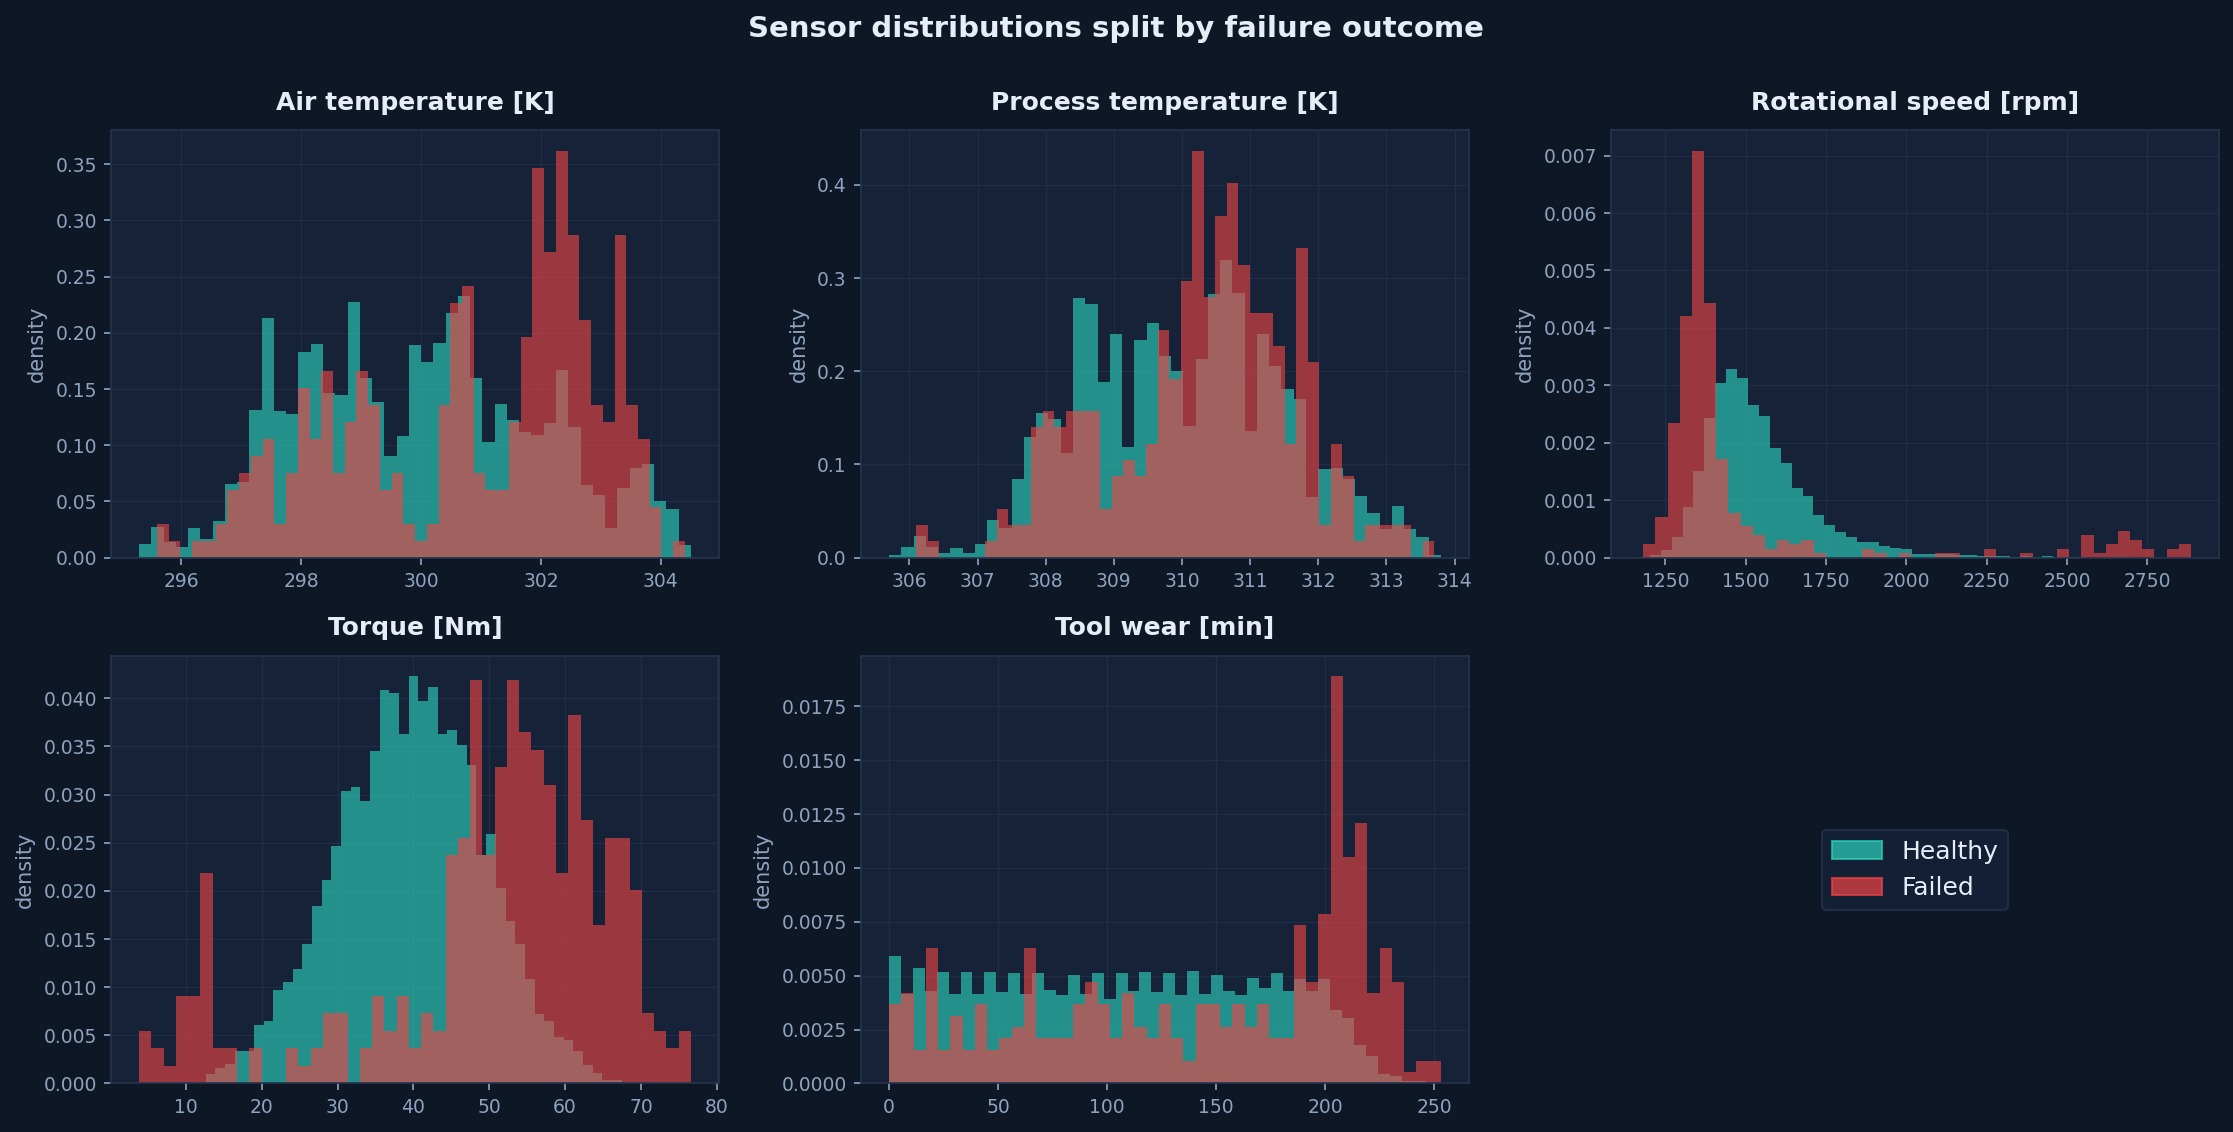

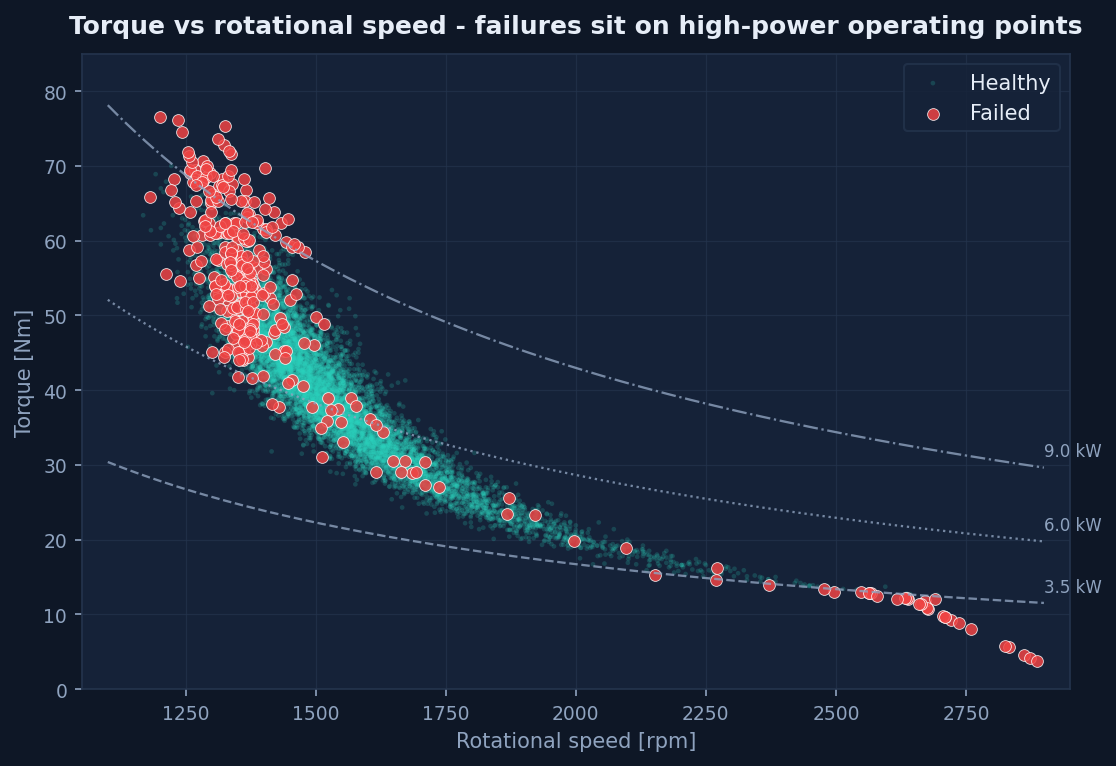

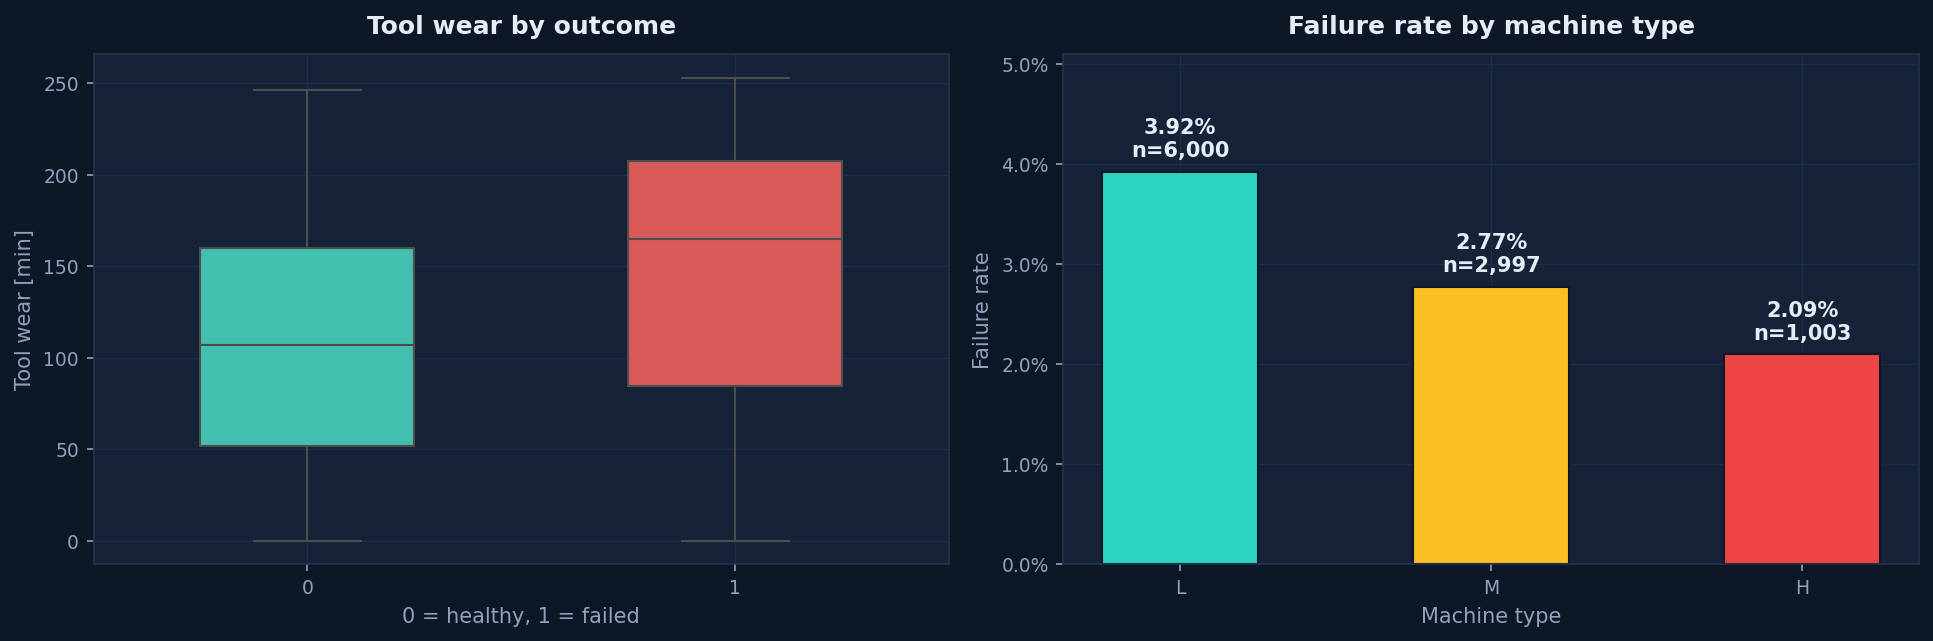

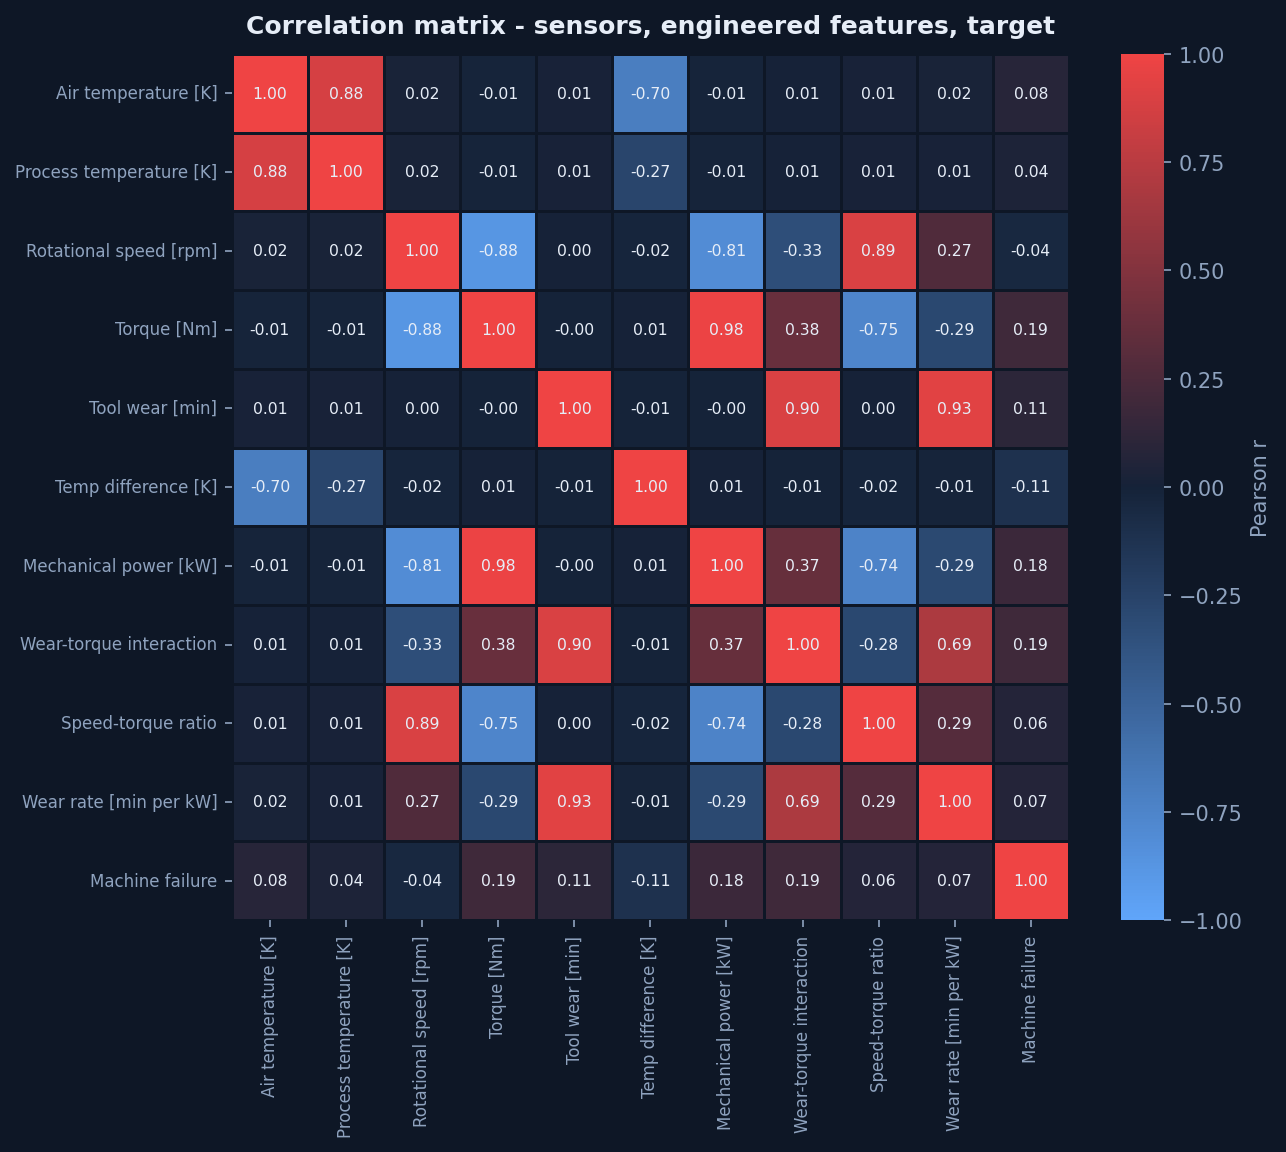

In [9]:
for name, width in [("02_sensor_distributions.png", 950),
                    ("05_torque_speed.png", 720),
                    ("06_wear_type.png", 900),
                    ("03_correlation.png", 700)]:
    display(Image(filename=str(C.FIG_DIR / name), width=width))

---
## ④ Modelling design

Four deliberate choices:

1. **Three models of increasing flexibility.** Logistic Regression is the transparent linear
   baseline; a depth-limited Decision Tree adds interactions and is fully readable; a Random
   Forest averages many trees to reduce variance. Comparing them shows *what* the extra
   flexibility buys.
2. **Class weights instead of resampling.** `class_weight='balanced'` reweights the loss so
   the 3.4% minority class is not ignored. No synthetic points are invented, so no SMOTE
   dependency and no risk of fabricating sensor readings that never occurred.
3. **Threshold tuned on training folds only.** With imbalanced data the default 0.5 cutoff is
   arbitrary. The cutoff is chosen to maximise F1 using *out-of-fold* training predictions;
   the test set is only ever used to report.
4. **Two splits, because one split can lie.** A random stratified split can leak
   near-duplicate operating conditions between train and test. A time-ordered split
   (train on the first 80% of runs, test on the last 20%) is stricter and closer to
   deployment.

And the exclusion list is explicit — the leakage columns never enter `X`:

In [10]:
X, y, excluded = modeling.build_design_matrix(df)
print(f"design matrix: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"failures     : {int(y.sum())} ({y.mean():.2%})")
print("\nEXCLUDED from all model inputs (leakage, target, outlier flags):")
for c in excluded:
    print("  ✗", c)
print("\nFEATURES USED:")
for c in X.columns:
    print("  ✓", c)

design matrix: 10,000 rows x 15 features
failures     : 339 (3.39%)

EXCLUDED from all model inputs (leakage, target, outlier flags):
  ✗ TWF
  ✗ HDF
  ✗ PWF
  ✗ OSF
  ✗ RNF
  ✗ Machine failure
  ✗ Air temperature [K] outlier
  ✗ Process temperature [K] outlier
  ✗ Rotational speed [rpm] outlier
  ✗ Torque [Nm] outlier
  ✗ Tool wear [min] outlier
  ✗ any_outlier

FEATURES USED:
  ✓ UDI
  ✓ Air temperature [K]
  ✓ Process temperature [K]
  ✓ Rotational speed [rpm]
  ✓ Torque [Nm]
  ✓ Tool wear [min]
  ✓ Temp difference [K]
  ✓ Mechanical power [kW]
  ✓ Wear-torque interaction
  ✓ Speed-torque ratio
  ✓ Wear rate [min per kW]
  ✓ Product ID serial
  ✓ Type_H
  ✓ Type_L
  ✓ Type_M


In [11]:
# Train all three models, evaluate, and explain (this is the same call `src/train.py` makes)
results = modeling.run_experiment(df)

rows = []
for key, val in results["classes"].items():
    m05, mt = val["test_at_0.5"], val["test_at_tuned"]
    rows.append({
        "model": f"{val['label']} ⭐" if key == results["best_model"] else val["label"],
        "threshold": round(val["tuned_threshold"], 3),
        "precision": mt["precision"], "recall": mt["recall"], "f1": mt["f1"],
        "f1 @0.50": m05["f1"],
        "PR-AUC": mt["pr_auc"], "ROC-AUC": mt["roc_auc"],
        "balanced acc": mt["balanced_accuracy"], "MCC": mt["mcc"],
        "accuracy": mt["accuracy"],
    })
leaderboard = pd.DataFrame(rows).set_index("model").round(3)
leaderboard

,threshold,precision,recall,f1,f1 @0.50,PR-AUC,ROC-AUC,balanced acc,MCC,accuracy
model,,,,,,,,,,
Logistic Regression,0.910,0.537,0.426,0.475,0.288,0.446,0.941,0.707,0.462,0.968
Decision Tree,0.950,0.911,0.750,0.823,0.553,0.835,0.909,0.874,0.821,0.989
Random Forest ⭐,0.440,0.946,0.779,0.855,0.855,0.883,0.979,0.889,0.855,0.991


### Reading the leaderboard

- **Accuracy is a trap here.** The Random Forest reaches 99.1% accuracy — but so does a
  model that predicts "healthy" for everything (96.6%) while catching **zero** failures.
  Precision, recall, F1, PR-AUC and MCC are reported for that reason.
- **Logistic Regression underperforms badly (F1 ≈ 0.48).** Its huge coefficient on
  `Speed-torque ratio` shows why: the real decision boundary is a ratio/interaction between
  speed and torque, which a linear model in raw features cannot represent. This is a
  *finding*, not a failure of the exercise — it tells you the physics is multiplicative.
- **Random Forest wins** (F1 0.855, PR-AUC 0.883) with very high precision (0.946) but
  recall 0.779: it misses roughly one failure in five.
- **The default 0.5 cutoff badly hurts Logistic Regression** (recall 0.882 at precision 0.172)
  — a concrete demonstration of why threshold choice is a decision, not a default.

Confusion matrices and discrimination curves:

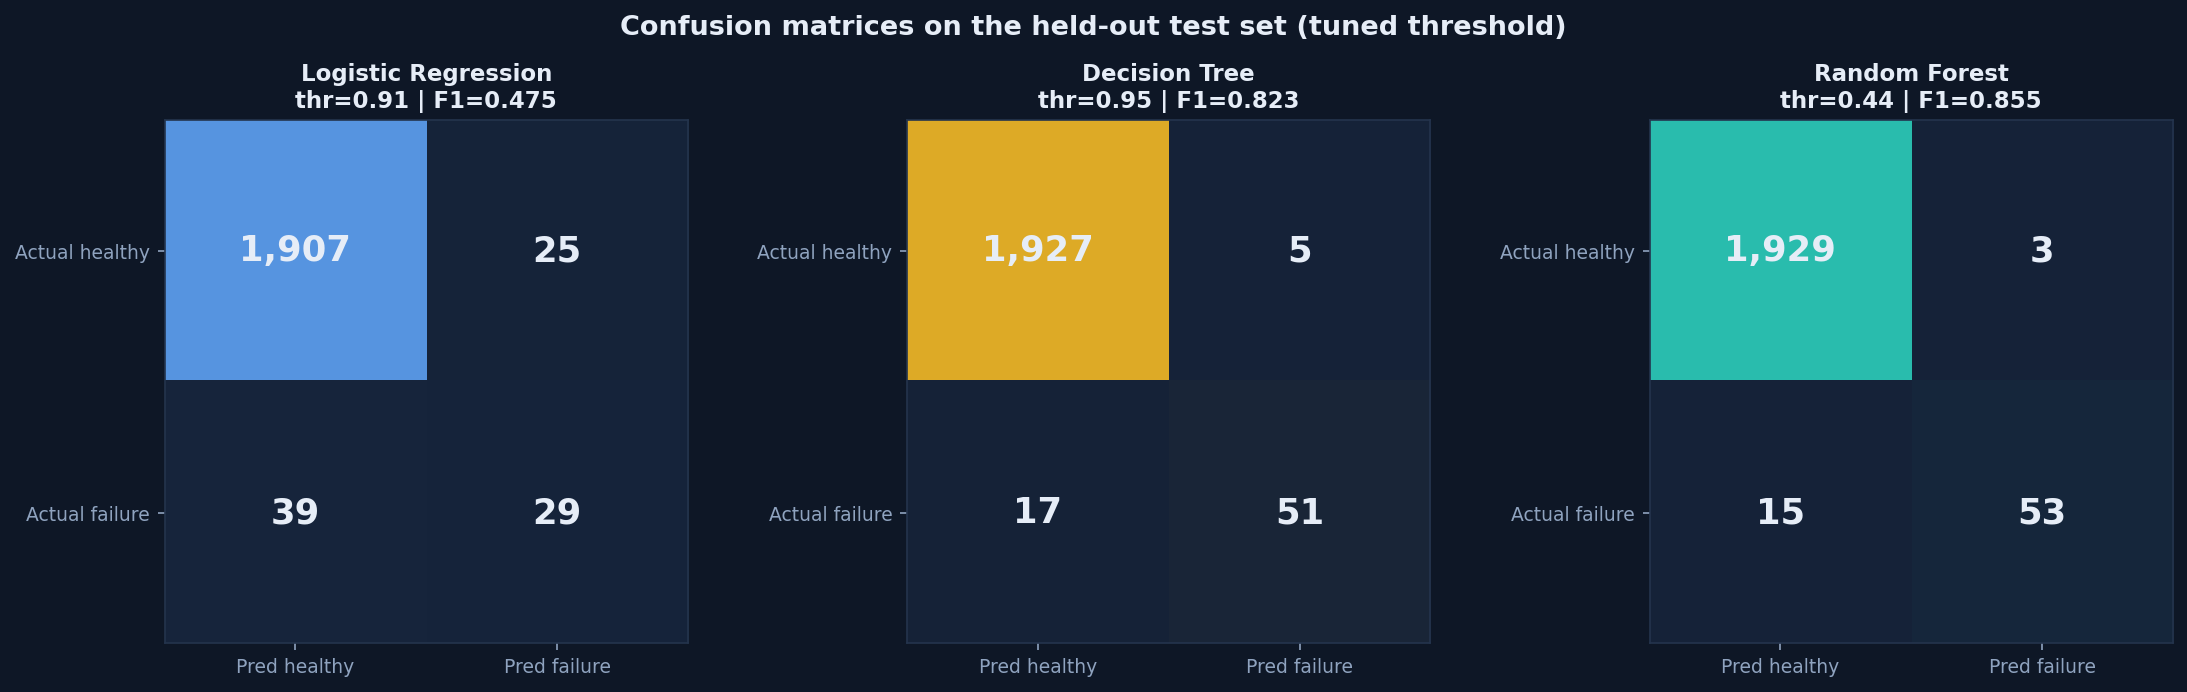

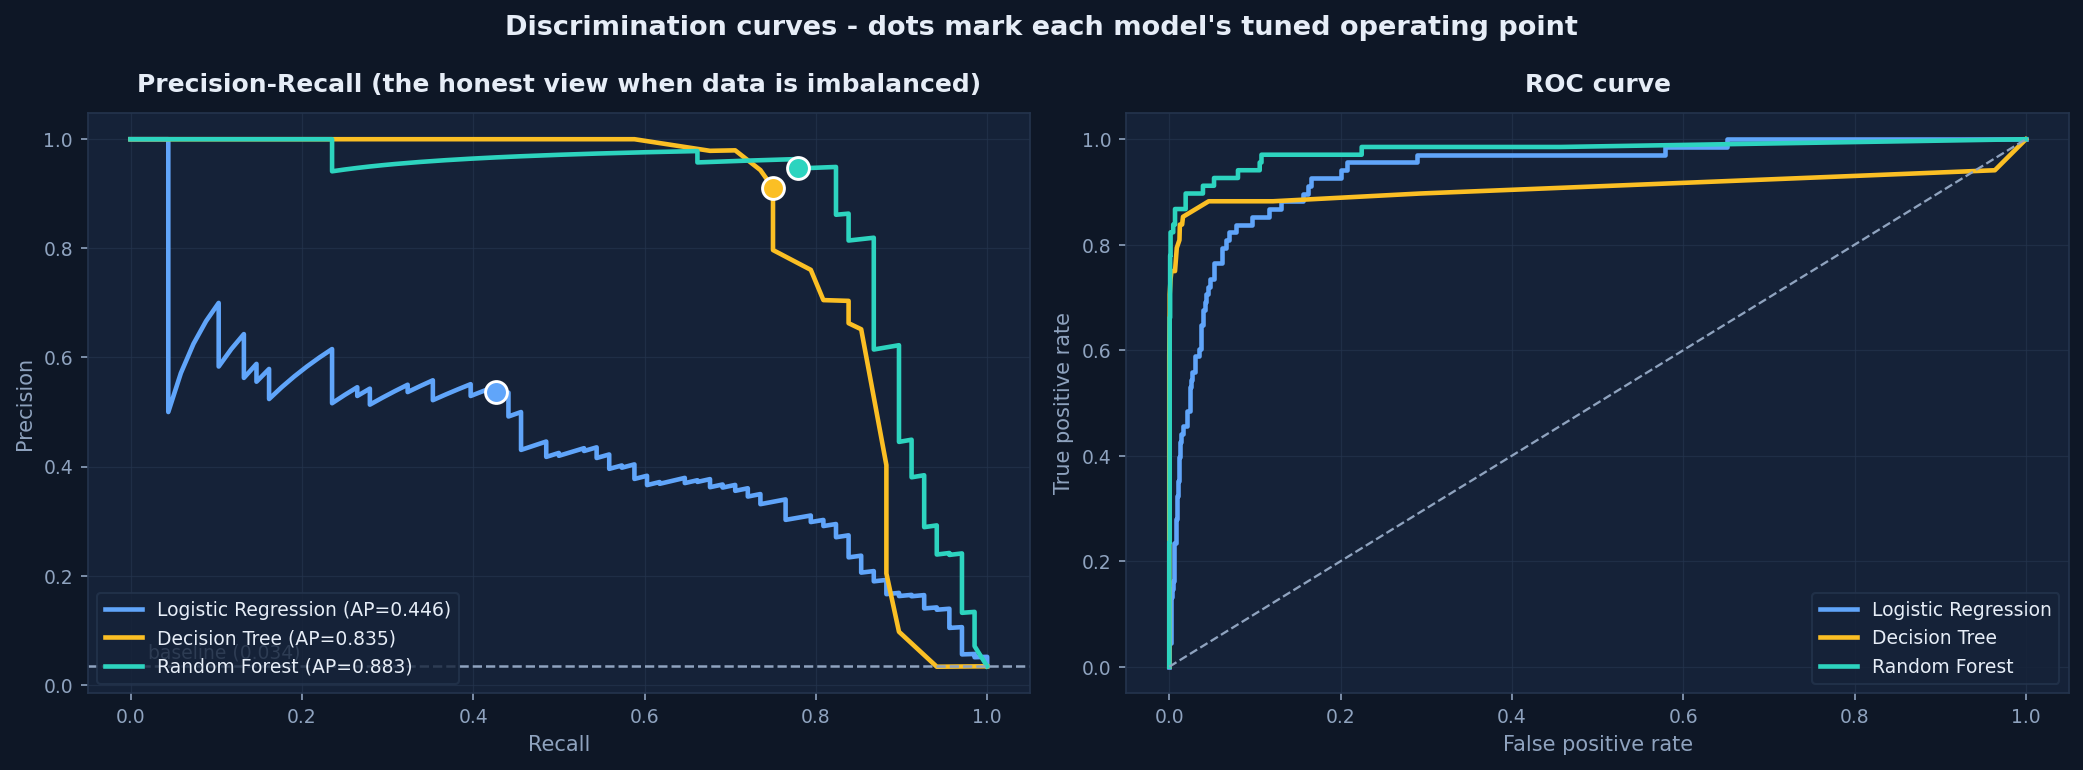

In [12]:
for name, width in [("07_confusion_matrices.png", 950), ("08_pr_roc.png", 900)]:
    display(Image(filename=str(C.FIG_DIR / name), width=width))

In [13]:
# Cross-validation stability (5-fold, inside the training set) and bootstrap CIs (test set)
cv_rows, ci_rows = [], []
for key, val in results["classes"].items():
    cv = val["cv"]["at_tuned"]
    ci = val["test_ci_at_tuned"]
    cv_rows.append({
        "model": val["label"],
        **{f"CV {m}": f"{cv[m]['mean']:.3f} ± {cv[m]['std']:.3f}"
           for m in ["precision", "recall", "f1", "pr_auc"]},
    })
    ci_rows.append({
        "model": val["label"],
        **{f"test {k} (95% CI)": f"{ci[k]['mean']:.3f} [{ci[k]['low']:.3f}–{ci[k]['high']:.3f}]"
           for k in ["f1", "precision", "recall"]},
    })
print("Cross-validation inside the training set:")
display(pd.DataFrame(cv_rows).set_index("model"))
print("Bootstrap 95% confidence intervals on the test set:")
display(pd.DataFrame(ci_rows).set_index("model"))

Cross-validation inside the training set:


,CV precision,CV recall,CV f1,CV pr_auc
model,,,,
Logistic Regression,0.518 ± 0.043,0.465 ± 0.065,0.487 ± 0.039,0.486 ± 0.048
Decision Tree,0.893 ± 0.064,0.797 ± 0.046,0.839 ± 0.019,0.857 ± 0.023
Random Forest,0.962 ± 0.012,0.745 ± 0.027,0.840 ± 0.021,0.887 ± 0.023


Bootstrap 95% confidence intervals on the test set:


,test f1 (95% CI),test precision (95% CI),test recall (95% CI)
model,,,
Logistic Regression,0.465 [0.343–0.571],0.521 [0.388–0.652],0.423 [0.303–0.543]
Decision Tree,0.819 [0.747–0.897],0.914 [0.835–0.982],0.744 [0.651–0.846]
Random Forest,0.854 [0.777–0.917],0.949 [0.879–1.000],0.777 [0.676–0.876]


Note the width of those intervals: F1 for the best model is 0.855 with a 95% CI of roughly
[0.78, 0.92] because the test set holds only 68 failures. Reporting "F1 = 0.855" without the
interval would overstate what we actually know.

---
## ⑤ The threshold is a maintenance policy, not a fact

A model outputs a probability. Turning that into "flag this machine" requires a cutoff, and
that cutoff encodes the business trade-off: a **missed failure** (false negative) is usually
far more expensive than a **wasted inspection** (false positive).

The tuned cutoff maximises F1 on out-of-fold training predictions. In the dashboard this is a
slider, so a maintenance team can move it toward recall (catch more) or precision (alarm less).

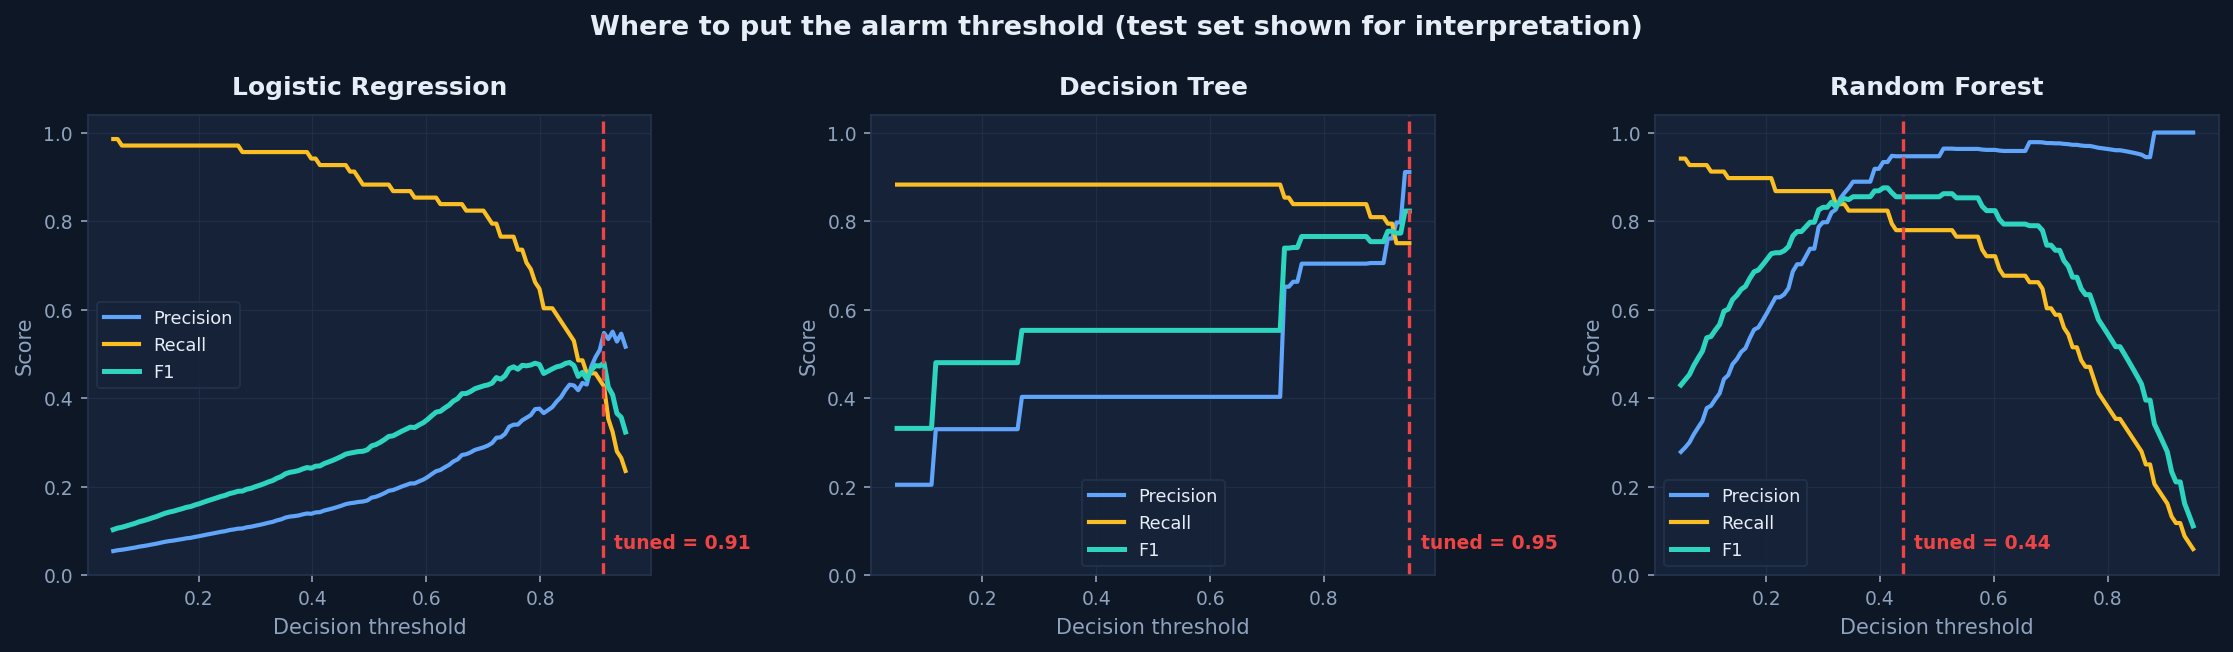

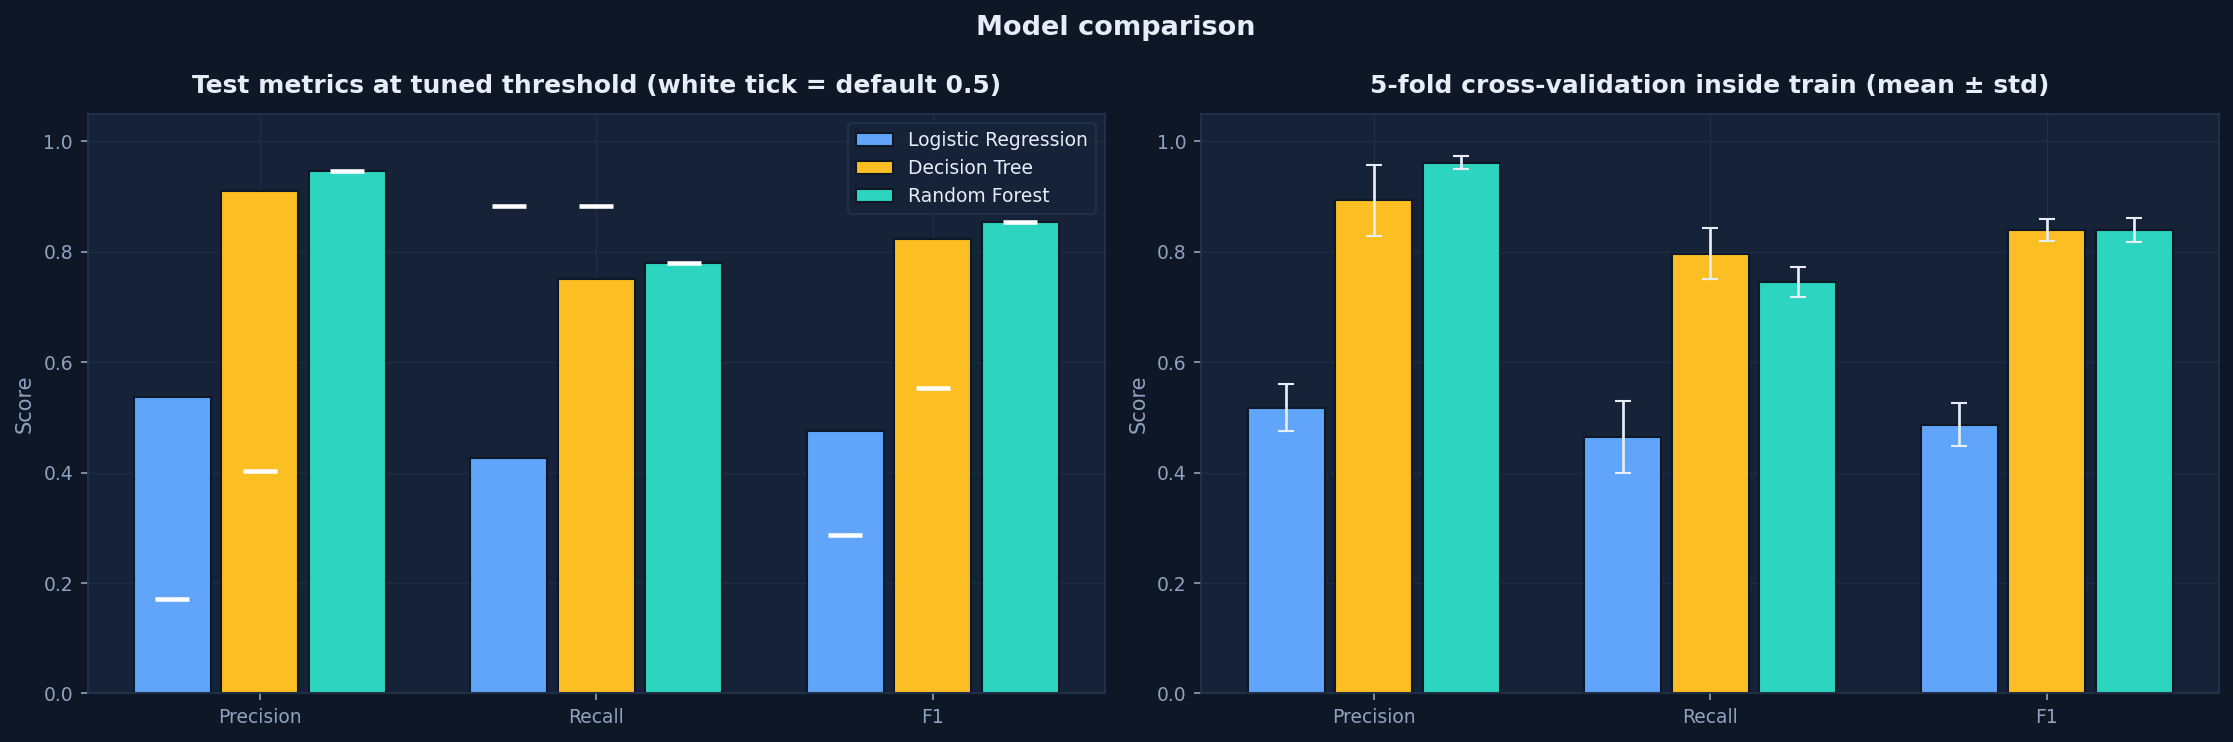

In [14]:
for name, width in [("09_thresholds.png", 950), ("10_model_comparison.png", 950)]:
    display(Image(filename=str(C.FIG_DIR / name), width=width))

In [15]:
# What the policy choice actually costs, using the best model on the test set
X_tr, X_te, y_tr, y_te = results["_random_split"]
best = results["_fitted"][results["best_model"]]
p_te = best.predict_proba(X_te)[:, 1]

trade = pd.DataFrame([
    {"policy": "very sensitive (catch everything)", "threshold": 0.10,
     **{k: v for k, v in modeling.metrics_at(y_te, p_te, 0.10).items()
        if k in ("precision", "recall", "f1", "fp", "fn")}},
    {"policy": "tuned for best F1", "threshold": results["classes"][results["best_model"]]["tuned_threshold"],
     **{k: v for k, v in modeling.metrics_at(
         y_te, p_te, results["classes"][results["best_model"]]["tuned_threshold"]).items()
        if k in ("precision", "recall", "f1", "fp", "fn")}},
    {"policy": "conservative (few false alarms)", "threshold": 0.80,
     **{k: v for k, v in modeling.metrics_at(y_te, p_te, 0.80).items()
        if k in ("precision", "recall", "f1", "fp", "fn")}},
]).set_index("policy").round(3)
print("fp = wasted inspections, fn = missed failures")
trade

fp = wasted inspections, fn = missed failures


,threshold,precision,recall,f1,fp,fn
policy,,,,,,
very sensitive (catch everything),0.100,0.380,0.912,0.537,101,6
tuned for best F1,0.440,0.946,0.779,0.855,3,15
conservative (few false alarms),0.800,0.963,0.382,0.547,1,42


The cell below restates that table in the only units a plant manager cares about: **how many
inspections do I do, and how many real failures do I miss?**

In [16]:
best_key = results["best_model"]
t_tuned = results["classes"][best_key]["tuned_threshold"]
total_failures = int(y_te.sum())
policies = {"very sensitive (0.10)": 0.10,
            f"tuned for best F1 ({t_tuned:.2f})": t_tuned,
            "conservative (0.80)": 0.80}
rows = []
for name, t in policies.items():
    m = modeling.metrics_at(y_te, p_te, t)
    rows.append({
        "maintenance policy": name,
        "inspections triggered": m["tp"] + m["fp"],
        "real failures caught": m["tp"],
        "real failures missed": m["fn"],
        "of which were false alarms": m["fp"],
        "share of failures caught": m["recall"],
    })
policy_df = pd.DataFrame(rows).set_index("maintenance policy")
print(f"Test set contains {total_failures} real failures out of {len(y_te):,} machines.")
policy_df

Test set contains 68 real failures out of 2,000 machines.


,inspections triggered,real failures caught,real failures missed,of which were false alarms,share of failures caught
maintenance policy,,,,,
very sensitive (0.10),163,62,6,101,0.912
tuned for best F1 (0.44),56,53,15,3,0.779
conservative (0.80),27,26,42,1,0.382


This is the most useful table in the notebook for a non-technical stakeholder, because it is
stated in inspections rather than in F1. Read it across: a sensitive policy triggers far more
inspections and catches more failures; a conservative policy keeps the workshop quiet and
misses many more failures. Which row is "right" depends on the cost of a missed failure versus
the cost of an inspection — an engineering and business decision, not a modelling one.

---
## ⑥ Does the random split flatter us?

Training and testing on a random split can overstate performance when rows from the same
operating regime land in both halves. The stricter test is to train on the **earlier** runs
and predict the **later** ones.

temporal test set: 39 failures (1.95%)


,random-split F1,time-split F1,random-split recall,time-split recall,Δ F1
model,,,,,
Logistic Regression,0.475,0.250,0.426,0.154,-0.225
Decision Tree,0.823,0.727,0.750,0.718,-0.095
Random Forest,0.855,0.727,0.779,0.718,-0.128


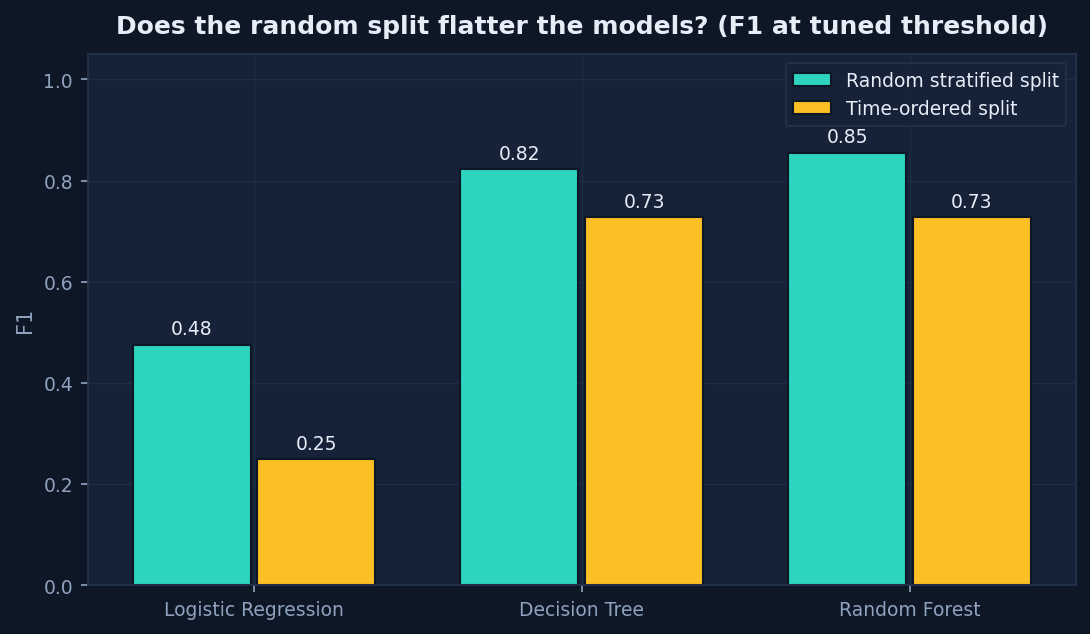

In [17]:
split_rows = []
for key, val in results["classes"].items():
    rnd = val["test_at_tuned"]
    tmp = results["splits"]["temporal"]["classes"][key]["test_at_tuned"]
    split_rows.append({
        "model": val["label"],
        "random-split F1": rnd["f1"], "time-split F1": tmp["f1"],
        "random-split recall": rnd["recall"], "time-split recall": tmp["recall"],
        "Δ F1": tmp["f1"] - rnd["f1"],
    })
print(f"temporal test set: {results['splits']['temporal']['test_failures']} failures "
      f"({results['splits']['temporal']['test_failure_rate']:.2%})")
display(pd.DataFrame(split_rows).set_index("model").round(3))
display(Image(filename=str(C.FIG_DIR / "14_split_comparison.png"), width=720))

**Honest conclusion:** the tree models drop from F1 ≈ 0.82–0.86 on the random split to
**0.727 on the time-ordered split** — roughly a 10–13 point drop. So yes, the random split
*was* somewhat flattering. Reporting only the random-split number would overstate real-world
expectations. (The temporal test set also has a lower failure rate, 1.95% vs 3.4%, which makes
it harder in a second way.)

---
## ⑦ Which inputs actually influence the predictions?

Three complementary views, deliberately chosen to check each other:

| Method | What it tells you | Weakness |
|---|---|---|
| **Permutation importance** (model-agnostic) | How much PR-AUC drops when a feature is shuffled | Correlated features share credit |
| **Gini / impurity importance** | How often a tree splits on the feature | Biased toward high-cardinality features |
| **Partial dependence** | Shape of risk vs one feature | Assumes features are independent |
| **LR coefficients** | Direction and size of a linear effect | Only valid for the linear model |

Where permutation and Gini importance disagree, prefer permutation importance.


=== permutation importance: Random Forest ===


,PR-AUC drop
feature,
Rotational speed [rpm],0.282
Temp difference [K],0.209
Wear-torque interaction,0.109
Mechanical power [kW],0.069
Tool wear [min],0.035
Torque [Nm],0.028
Speed-torque ratio,0.018
Wear rate [min per kW],0.014



=== permutation importance: Decision Tree ===


,PR-AUC drop
feature,
Temp difference [K],0.465
Speed-torque ratio,0.396
Rotational speed [rpm],0.380
Mechanical power [kW],0.267
Wear-torque interaction,0.211
Product ID serial,0.036
Wear rate [min per kW],0.022
Tool wear [min],0.019


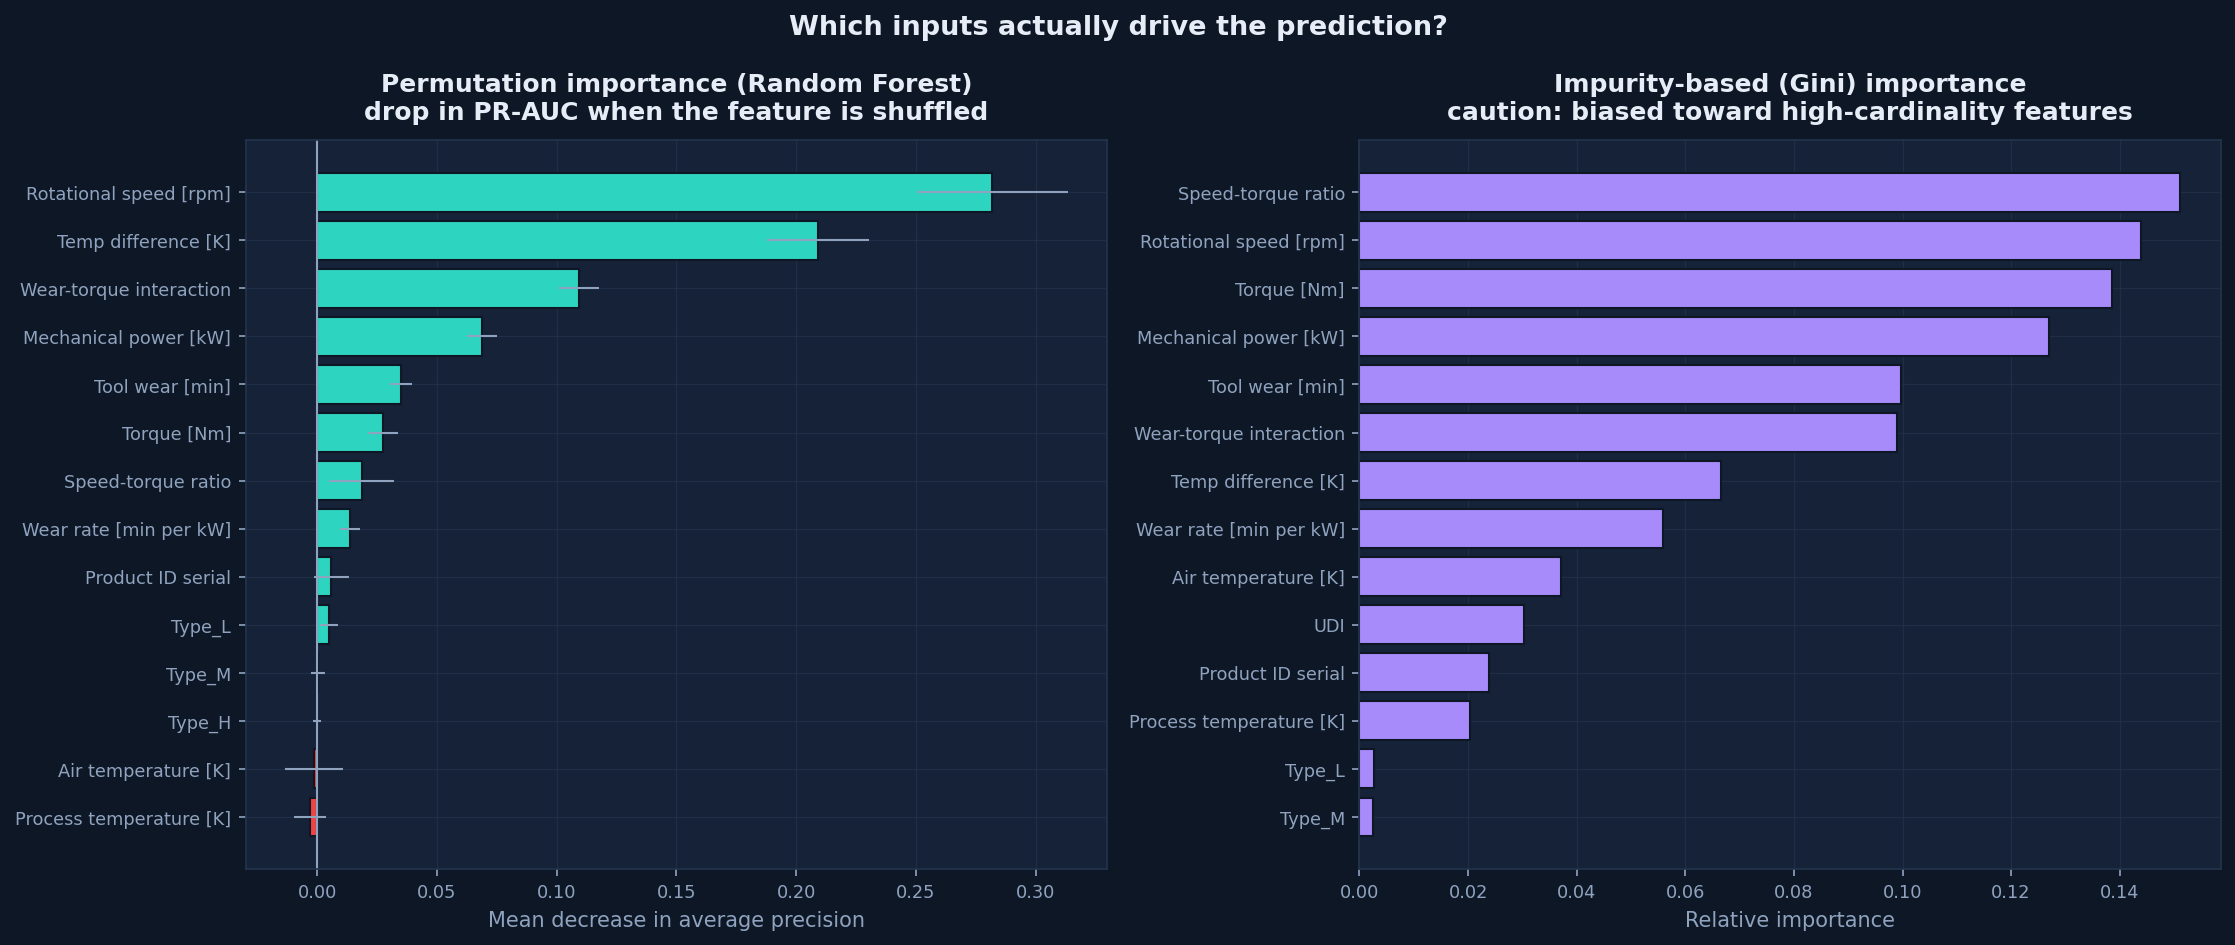

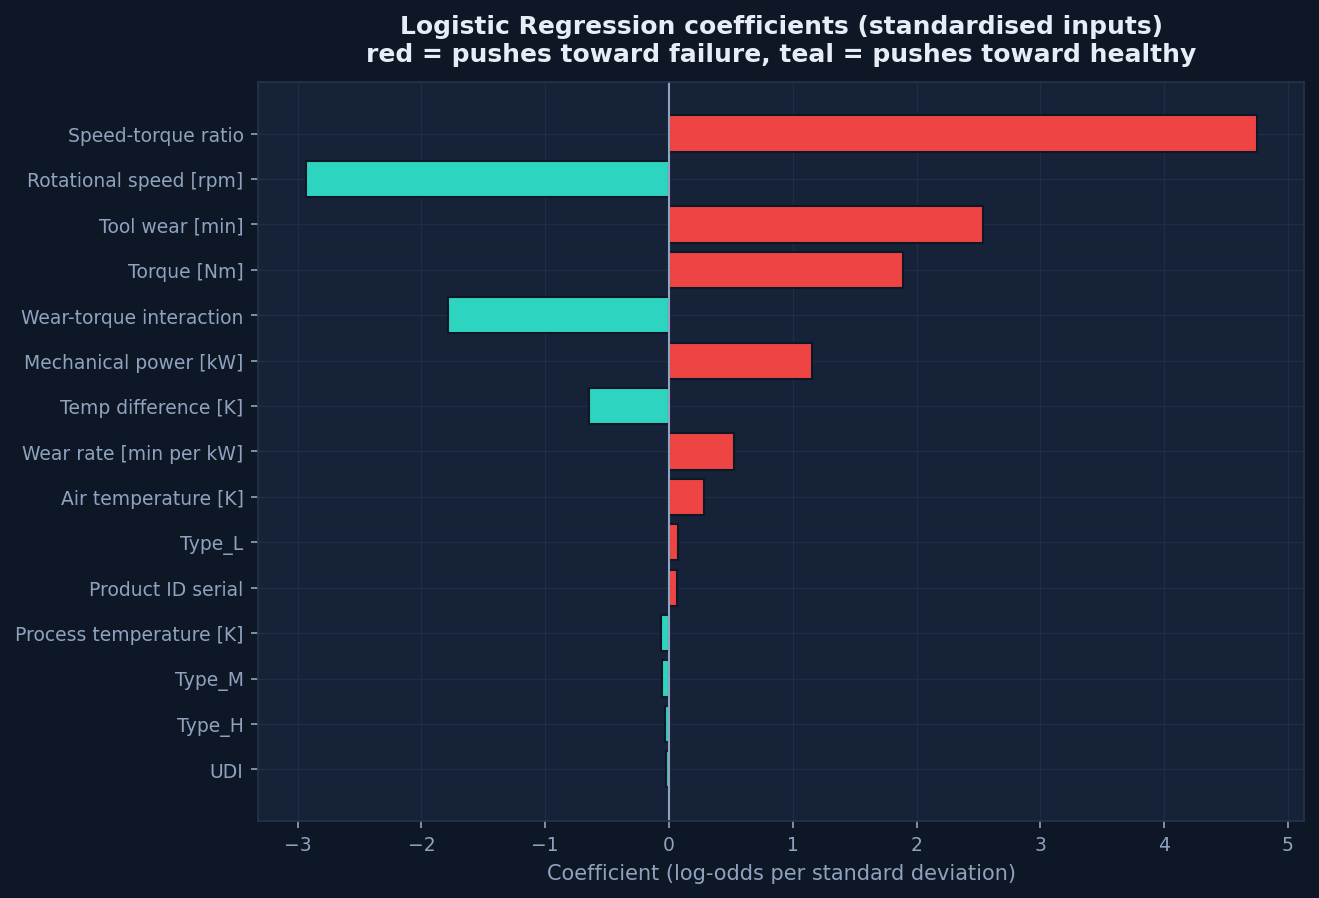

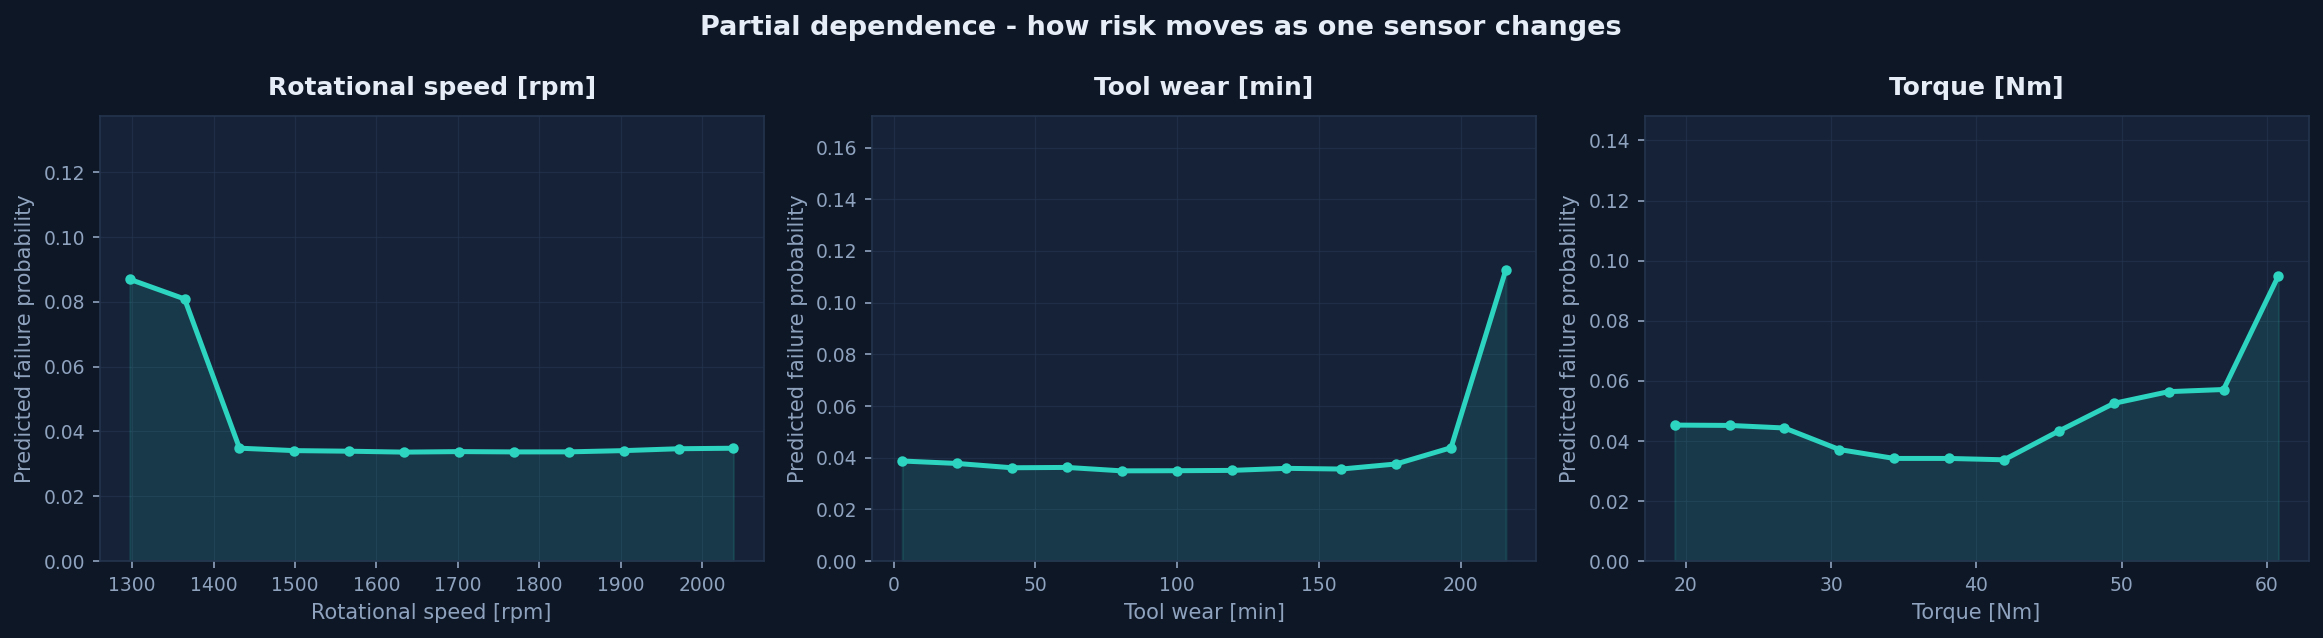

In [18]:
for key in ["random_forest", "decision_tree"]:
    imp = results["classes"][key]["explanation"]["permutation_importance"]["ranked"]
    top = pd.DataFrame(list(imp.items())[:8], columns=["feature", "PR-AUC drop"])
    print(f"\n=== permutation importance: {results['classes'][key]['label']} ===")
    display(top.round(4).set_index("feature"))

display(Image(filename=str(C.FIG_DIR / "11_feature_importance.png"), width=980))
display(Image(filename=str(C.FIG_DIR / "12_lr_coefficients.png"), width=720))
display(Image(filename=str(C.FIG_DIR / "13_partial_dependence.png"), width=980))

In [19]:
# Do the ID columns the user asked to keep carry any signal?
imp = results["classes"][results["best_model"]]["explanation"]["permutation_importance"]
ranked = imp["ranked"]
total = sum(abs(v) for v in ranked.values()) or 1
id_feats = {k: v for k, v in ranked.items() if k in ("UDI", "Product ID serial")}
position = {k: i + 1 for i, k in enumerate(ranked)}
print("Identifier features kept as model inputs (deliberately, as an experiment):")
for k, v in id_feats.items():
    print(f"  {k:<20} PR-AUC drop = {v:+.5f}   rank {position.get(k, '—')} of {len(ranked)}")
print(f"\ncombined share of total permutation importance: "
      f"{sum(abs(v) for v in id_feats.values()) / total:.2%}")

Identifier features kept as model inputs (deliberately, as an experiment):
  Product ID serial    PR-AUC drop = +0.00591   rank 9 of 15
  UDI                  PR-AUC drop = -0.00460   rank 15 of 15

combined share of total permutation importance: 1.34%


### What the drivers are, and why they make physical sense

The forest's top drivers are **rotational speed**, **temperature difference**, **wear–torque
interaction** and **mechanical power** — i.e. exactly the quantities the failure mechanisms in
this machine depend on:

- **Speed and torque together** define the operating point. Failures cluster at high torque
  and low speed (high power), matching the overstrain and power failure modes.
- **`Temp difference` ranking near the top** is the heat-dissipation mechanism: when the
  process runs hot relative to ambient air, the machine cannot shed heat and HDF risk rises.
- **`Wear-torque interaction`** captures cumulative strain — a worn tool under load.
- **The ID columns are confirmed noise.** In the Random Forest they rank 9th (`Product ID
  serial`) and 15th of 15 (`UDI`) with a combined 1.3% of total permutation importance, and
  `UDI`'s contribution is actually *negative* (shuffling it slightly helps, i.e. it is
  acting as noise). That is the evidence for dropping them. They are retained only because
  keeping them was an explicit — and now empirically answered — question.

---
## ⑧ Scoring a new machine

The dashboard builds one row and pushes it through the **same** cleaning → feature → design
matrix code used in training. Doing this in one place is what prevents train/serve skew —
a very common cause of models that look great in a notebook and fail in production.

Below, we score a hypothetical high-risk machine and a healthy one.

In [20]:
bundle = __import__("joblib").load(C.MODELS_PATH)
best_key = bundle["best_model"]
threshold = bundle["tuned_thresholds"][best_key]
model = bundle["models"][best_key]

def score(air, proc, rpm, torque, wear, mtype):
    raw_row = pd.DataFrame([{
        "UDI": 1, "Product ID": f"{mtype}00001", "Type": mtype,
        "Air temperature [K]": air, "Process temperature [K]": proc,
        "Rotational speed [rpm]": rpm, "Torque [Nm]": torque, "Tool wear [min]": wear,
        C.TARGET: 0, "TWF": 0, "HDF": 0, "PWF": 0, "OSF": 0, "RNF": 0,
    }])
    cleaned_row, _, _ = cleaning.clean(raw_row)
    featured = cleaning.build_features(cleaned_row)
    X_row, _, _ = modeling.build_design_matrix(featured)
    X_row = X_row.reindex(columns=bundle["feature_names"], fill_value=0.0)
    out = {k: float(m.predict_proba(X_row)[:, 1][0]) for k, m in bundle["models"].items()}
    return out, X_row

cases = {
    "high-power overstrain (68 Nm @ 1330 rpm)": (299.0, 309.5, 1330, 68.0, 60, "L"),
    "worn tool under load (55 Nm, 235 min)":    (300.0, 310.0, 1450, 55.0, 235, "M"),
    "heat-dissipation risk (303.8/313.1 K)":    (303.8, 313.1, 1300, 62.0, 180, "H"),
    "healthy reference":                        (298.2, 308.7, 1500, 40.0, 20, "M"),
}

table = []
for label, args in cases.items():
    probs, X_row = score(*args)
    table.append({
        "machine": label,
        **{f"{modeling.MODEL_LABELS[k]}": f"{v:.1%}" for k, v in probs.items()},
        f"flagged @{threshold:.2f}": "YES" if probs[best_key] >= threshold else "no",
    })
pd.DataFrame(table).set_index("machine")

,Logistic Regression,Decision Tree,Random Forest,flagged @0.44
machine,,,,
high-power overstrain (68 Nm @ 1330 rpm),94.1%,100.0%,85.5%,YES
"worn tool under load (55 Nm, 235 min)",72.9%,98.5%,46.7%,YES
heat-dissipation risk (303.8/313.1 K),96.5%,0.0%,43.8%,no
healthy reference,0.4%,1.1%,0.2%,no


Each of these is a **probability**, not a verdict. A "91%" reading means the sensor pattern
resembles historical failures — a human should still inspect the machine. A "0.2%" reading
does not certify the machine is healthy.

---
## ⑨ Limitations (the part that should temper every number above)

1. **Simulated data.** AI4I 2020 is generated, not logged. Absolute performance will not
   transfer to a real plant; only the *method* transfers.
2. **Small number of failures.** 339 failures, 68 in the test set → F1 CIs of roughly ±0.07.
   A different random seed moves results by several points.
3. **Unlearnable failures exist.** The 19 random-failure (`RNF`) records have no sensor
   signature, capping recall. Chasing 100% recall is chasing noise.
4. **Label noise.** 18 rows flag a failure mode while labelled healthy; 9 failures have no
   flag. We preserved the published target rather than silently rewriting it.
5. **No per-machine time history.** Every row is an independent run, so degradation trends
   (the strongest real-world signal) cannot be captured here.
6. **Feature importance is not causality.** "The model used speed" does not mean "change the
   speed to prevent failure". Never act on importance charts without engineering review.
7. **The threshold is a policy choice** tuned on this dataset. A real deployment must re-tune
   it against actual maintenance costs.
8. **Not a safety system.** This is decision support for prioritising inspections. It must not
   be used as an automatic shutdown or safety case.

In [21]:
final = pd.DataFrame([{
    "model": v["label"],
    "test precision": v["test_at_tuned"]["precision"],
    "test recall": v["test_at_tuned"]["recall"],
    "test F1": v["test_at_tuned"]["f1"],
    "test PR-AUC": v["test_at_tuned"]["pr_auc"],
    "time-split F1": results["splits"]["temporal"]["classes"][k]["test_at_tuned"]["f1"],
} for k, v in results["classes"].items()]).set_index("model").round(3)
print("FINAL SUMMARY — held-out test set, tuned threshold")
display(final)
print(f"best model          : {modeling.MODEL_LABELS[results['best_model']]}")
print(f"tuned threshold     : {results['classes'][results['best_model']]['tuned_threshold']:.3f}")
print(f"failure rate in data: {y.mean():.2%}")
print("\nRun the dashboard locally with:  make app   (or: streamlit run app/streamlit_app.py)")

FINAL SUMMARY — held-out test set, tuned threshold


,test precision,test recall,test F1,test PR-AUC,time-split F1
model,,,,,
Logistic Regression,0.537,0.426,0.475,0.446,0.250
Decision Tree,0.911,0.750,0.823,0.835,0.727
Random Forest,0.946,0.779,0.855,0.883,0.727


best model          : Random Forest
tuned threshold     : 0.440
failure rate in data: 3.39%

Run the dashboard locally with:  make app   (or: streamlit run app/streamlit_app.py)


---
## ⑩ Conclusion

- A Random Forest on sensor data plus physics-motivated features reaches **F1 ≈ 0.86 /
  PR-AUC ≈ 0.88** on a random holdout, dropping to **F1 ≈ 0.73** under a strict time-ordered
  split. The second number is the honest expectation.
- **Linear models are insufficient** for this problem: the risk boundary is multiplicative in
  speed and torque, so Logistic Regression plateaus near F1 0.48.
- The drivers are interpretable and physically plausible — speed, temperature difference,
  wear–torque interaction and mechanical power — which is what makes the model usable as
  decision support rather than a black box.
- The largest risks to validity are **data provenance (simulated)**, **few failures** and
  **unlearnable random failures**. These are stated up front, not buried.
- **No prediction here is a guaranteed failure.** Each one is a prioritisation hint for a
  human inspector.

**Next steps that would genuinely improve this:** per-machine time-series data, cost-sensitive
threshold selection, drift monitoring in production, and a periodic re-validation schedule.